In [1]:
import preprocessing
import pandas as pd
import vectorization
from models import load_data, train_models, evaluate_models, save_models, create_models
import feature_engineering

import warnings
warnings.filterwarnings("ignore")

#### 1. Load dataset

In [2]:
data = preprocessing.load_data()
print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (50000, 2)
                                              review  sentiment
0  One of the other reviewers has mentioned that ...          1
1  A wonderful little production. <br /><br />The...          1
2  I thought this was a wonderful way to spend ti...          1
3  Basically there's a family where a little boy ...          0
4  Petter Mattei's "Love in the Time of Money" is...          1


#### 2. Check class distribution



Class distribution:
          count  percentage
Negative  25000        50.0
Positive  25000        50.0

The dataset is approximately balanced.


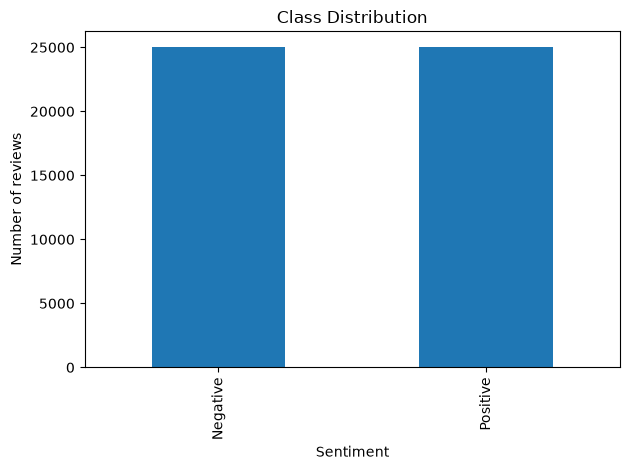

In [3]:
preprocessing.check_class_distribution(data)


#### 3. Preprocess reviews

In [4]:

print("\nPreprocessing reviews...")
data["clean_review"] = data["review"].apply(
    lambda review: preprocessing.preprocess_text(
        review, keep_sentiment_words=True
    )
)


Preprocessing reviews...


#### 4. Save all preprocessed data

In [5]:
from pathlib import Path
from sklearn.model_selection import train_test_split

PROCESSED_DIR = Path("./data/processed")


data.to_csv(
    PROCESSED_DIR / "imdb_preprocessed.csv",
    index=False
)

# 4. Split: 60% train, 20% validation, 20% test
X = data["clean_review"]
y = data["sentiment"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


#### 5. Save each split

In [6]:
train_data = pd.DataFrame({
    "review": X_train,
    "raw_review": data.loc[X_train.index, "review"],
    "sentiment": y_train
})

valid_data = pd.DataFrame({
    "review": X_valid,
    "raw_review": data.loc[X_valid.index, "review"],
    "sentiment": y_valid
})

test_data = pd.DataFrame({
    "review": X_test,
    "raw_review": data.loc[X_test.index, "review"],
    "sentiment": y_test
})

train_data.to_csv(PROCESSED_DIR / "train.csv", index=False)
valid_data.to_csv(PROCESSED_DIR / "validation.csv", index=False)
test_data.to_csv(PROCESSED_DIR / "test.csv", index=False)

In [7]:
X_train, X_test = vectorization.load_data()

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 30000
Testing reviews: 10000


\nTask 2.1: Bag-of-Words


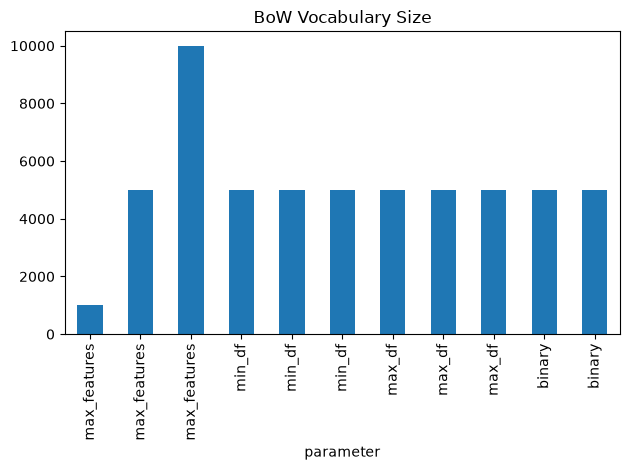

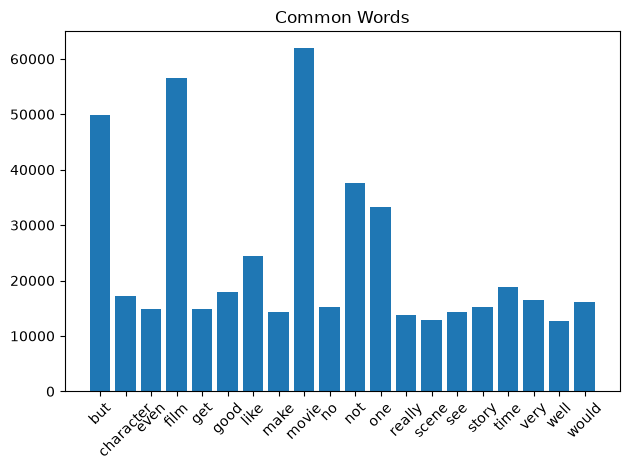

,parameter,value,vocabulary_size,sparsity,time_seconds
0,max_features,1000,1000,0.942380,2.429336
1,max_features,5000,5000,0.983624,2.345688
2,max_features,10000,10000,0.991110,2.322634
3,min_df,2,5000,0.983624,2.317767
4,min_df,5,5000,0.983624,2.202713
5,min_df,10,5000,0.983624,2.086035
6,max_df,0.8,5000,0.983624,2.102609
7,max_df,0.9,5000,0.983624,2.078523
8,max_df,1.0,5000,0.983624,2.093305
9,binary,True,5000,0.983593,2.079491


In [8]:
print("\\nTask 2.1: Bag-of-Words")
vectorization.bow_experiments(X_train)

\nTask 2.2: TF-IDF


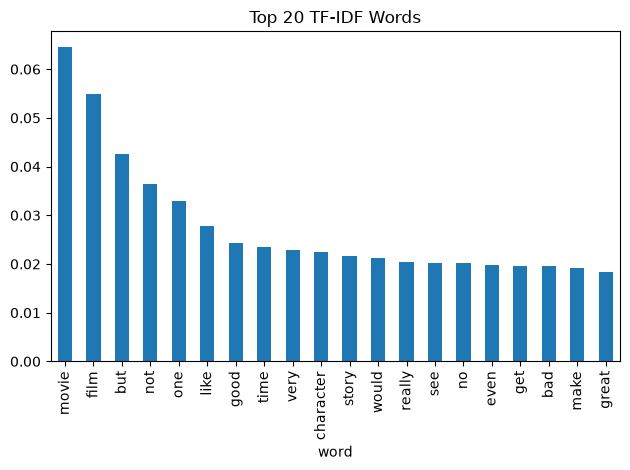

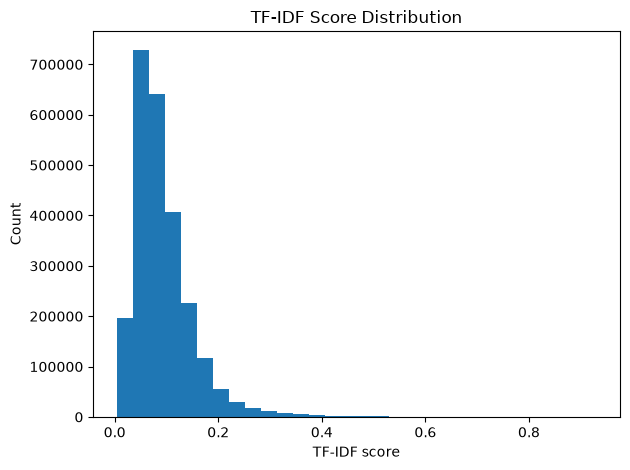

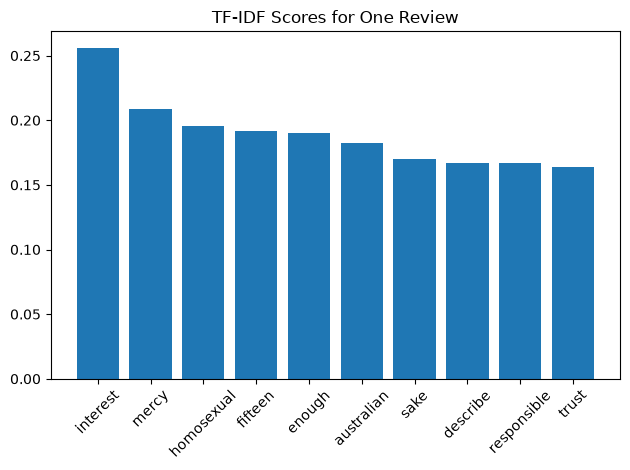

In [9]:

print("\\nTask 2.2: TF-IDF")
tfidf_results, tfidf = vectorization.tfidf_experiments(X_train)


\nTask 2.3: N-grams
\nTop Bigram features:
['but not' 'look like' 've seen' 'ever seen' 'movie but' 'year old'
 'very good' 'special effect' 'film but' 'movie not']
\nTop Trigram features:
['ve ever seen' 'worst movie ever' 'movie ever seen' 'movie ever made'
 'movie ve ever' 'movie ve seen' 'film ever made' 'one worst movie'
 'film ve seen' 'new york city']


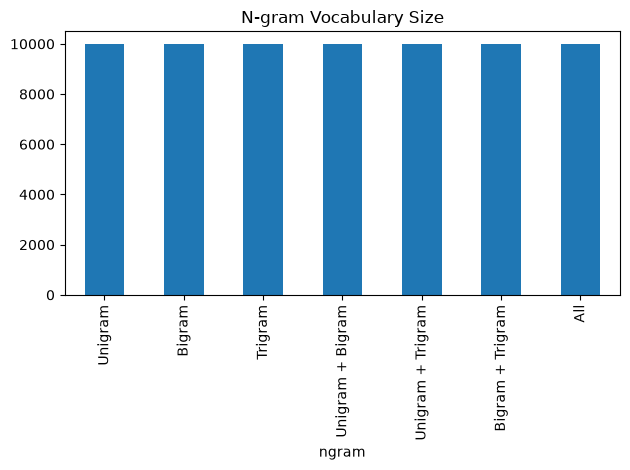

,ngram,vocabulary_size,sparsity,time_seconds
0,Unigram,10000,0.991110,2.417940
1,Bigram,10000,0.997806,10.098226
2,Trigram,10000,0.999648,13.527435
3,Unigram + Bigram,10000,0.990057,11.110988
4,Unigram + Trigram,10000,0.990041,25.086911
5,Bigram + Trigram,10000,0.997768,23.481129
6,All,10000,0.990041,26.041665


In [10]:
print("\\nTask 2.3: N-grams")
vectorization.ngram_experiments(X_train)

In [11]:
print("\\nTask 2.4: Character n-grams")
char_vectorizer = vectorization.character_ngrams(X_train)

\nTask 2.4: Character n-grams

Character n-grams
Vocabulary size: 10000
Matrix shape: (30000, 10000)
Sparsity: 0.8796714566666667
Time taken: 27.23 seconds


In [12]:
print("\\nAll vectorization tasks completed.")

\nAll vectorization tasks completed.


In [13]:
# Run the complete model training and evaluation
X_train, X_test, y_train, y_test = load_data()

In [14]:
models, training_times, best_parameters = train_models(
    X_train, y_train
)


 Training: Multinomial NB
Best parameters: {'model__alpha': 1.0}
Best CV score: 0.8491898447350202
Training time: 35.61 seconds

 Training: Bernoulli NB
Training time: 2.21 seconds

 Training: Logistic Regression
Best parameters: {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
Best CV score: 0.885821657245599
Training time: 122.23 seconds

 Training: Linear SVM
Best parameters: {'model__C': 0.1, 'model__max_iter': 2000}
Best CV score: 0.8857533997712567
Training time: 122.47 seconds

 Training: Random Forest
Training time: 17.73 seconds

 Training: KNN
Training time: 3.24 seconds

 Training: Gradient Boosting
Training time: 95.2 seconds



Evaluating: Multinomial NB

Classification Report: Multinomial NB
              precision    recall  f1-score   support

    Negative       0.84      0.85      0.85      5000
    Positive       0.85      0.84      0.84      5000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000


Evaluating: Bernoulli NB

Classification Report: Bernoulli NB
              precision    recall  f1-score   support

    Negative       0.85      0.85      0.85      5000
    Positive       0.85      0.85      0.85      5000

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000


Evaluating: Logistic Regression

Classification Report: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      5000
    Positive       0.88      0

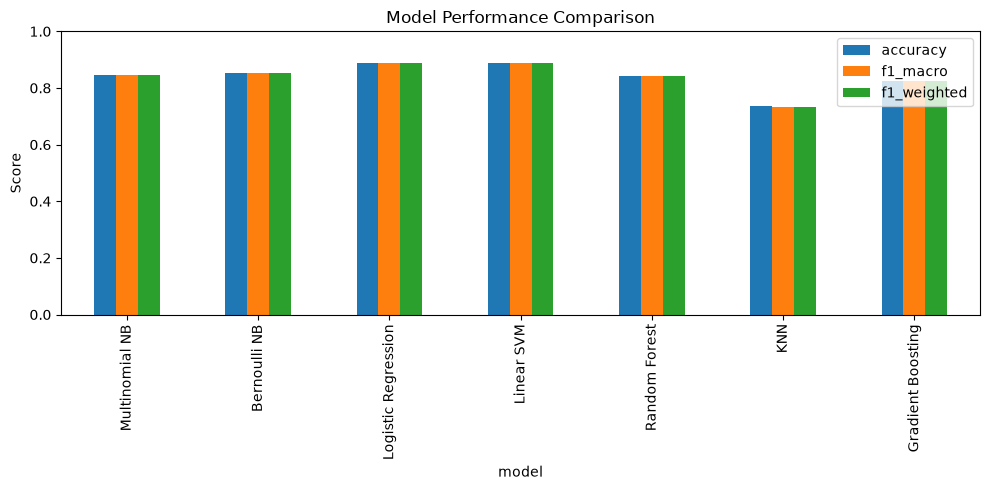

In [15]:
# Evaluate the trained models
results = evaluate_models(models, X_test, y_test)

In [16]:
save_models(models, training_times, best_parameters)

print("\nFinal Results:")
display(results)
print("\nModels saved in the models folder.")


Final Results:


,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc,prediction_time
0,Multinomial NB,0.8443,0.844358,0.8443,0.844293,0.844358,0.8443,0.844293,0.912740,0.918009
1,Bernoulli NB,0.8519,0.851902,0.8519,0.851900,0.851902,0.8519,0.851900,0.922735,0.867256
2,Logistic Regression,0.8880,0.888168,0.8880,0.887988,0.888168,0.8880,0.887988,0.955885,0.783706
3,Linear SVM,0.8876,0.887839,0.8876,0.887583,0.887839,0.8876,0.887583,0.956147,0.895837
4,Random Forest,0.8425,0.842669,0.8425,0.842481,0.842669,0.8425,0.842481,0.921501,0.910954
5,KNN,0.7351,0.739732,0.7351,0.733814,0.739732,0.7351,0.733814,0.806035,9.958944
6,Gradient Boosting,0.8249,0.825173,0.8249,0.824863,0.825173,0.8249,0.824863,0.904839,0.953605



Models saved in the models folder.


In [ ]:
X_train, X_test, raw_train, raw_test, y_train, y_test = feature_engineering.load_data()

# Extract and combine custom and TF-IDF features
train_text, test_text, train_combined, test_combined = feature_engineering.combine_features(
    X_train, X_test, raw_train, raw_test
)

print("Custom feature examples:")
display(feature_engineering.extract_features(raw_train).head())

Custom feature examples:
   character_count  word_count  average_word_length  sentence_count  \
0              741         140             4.235714               5   
1              982         161             4.857143               7   
2              700         135             4.014815              13   
3             4012         724             4.352210              32   
4              322          68             3.544118               4   

   exclamation_count  capital_ratio  positive_word_count  negative_word_count  \
0                  0       0.016194                    0                    2   
1                  0       0.011202                    1                    0   
2                  1       0.025714                    0                    0   
3                  1       0.022433                    4                    5   
4                  0       0.015528                    0                    0   

   polarity_ratio  has_amazing  has_terrible  has_worst  rati


Feature selection comparison
            Vectorization / Features  Accuracy  F1-Score  \
0          BoW (5k) + Multinomial NB    0.8443  0.844293   
1  TF-IDF (5k) + Logistic Regression    0.8882  0.888188   
2                TF-IDF + Chi-square    0.8799  0.879891   
3        TF-IDF + Mutual Information    0.8640  0.863971   
4              TF-IDF + L1 Selection    0.8360  0.835937   

   Training Time (seconds)  Inference Time (seconds)  
0                 0.010830                  0.004628  
1                 0.140009                  0.001621  
2                 0.112371                  0.001154  
3                 0.184001                  0.001316  
4                 0.041915                  0.000890  


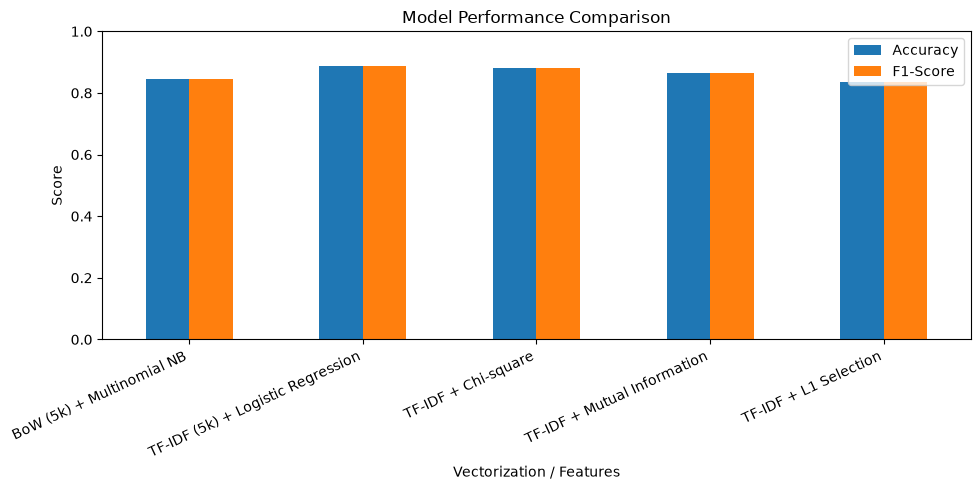

In [18]:
print("\nFeature selection comparison")

selection_results = feature_engineering.compare_features(
    X_train, y_train, X_test, y_test
)

feature_engineering.save_comparison(
    selection_results,
    "feature_selection_comparison.csv"
)

\nCustom feature comparison


   Vectorization / Features  Accuracy  F1-Score  Training Time (seconds)  \
0               TF-IDF only    0.8882  0.888188                 0.369246   
1  TF-IDF + Custom Features    0.8835  0.883492                 2.247590   

   Inference Time (seconds)  
0                  0.004523  
1                  0.007580  


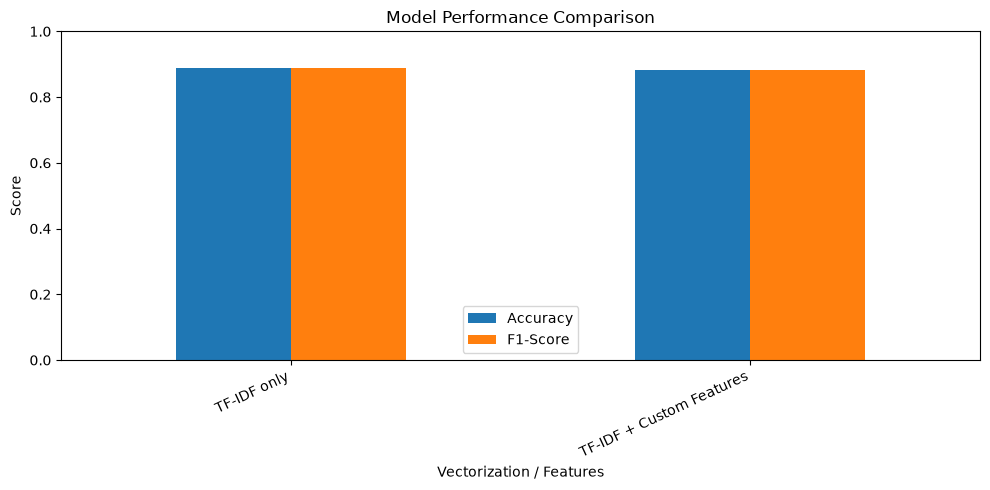

\nFeature engineering tasks completed.


In [19]:

# Compare custom features
print("\\nCustom feature comparison")
custom_results = feature_engineering.compare_custom_features(
    train_text, test_text, train_combined, test_combined,
    y_train, y_test
)
feature_engineering.save_comparison(custom_results, "custom_feature_comparison.csv")

print("\\nFeature engineering tasks completed.")
